In [1]:
# ============================================================
# SMARTVISION AI - FINAL DATASET EDA
# Phase 1 - Step 1.2: Exploratory Data Analysis
# ============================================================

import os
import random
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image

# ------------------------------------------------------------
# Final dataset paths
# ------------------------------------------------------------

BASE_DIR = Path(r"E:\SmartVision-AI\data\final_dataset")
CLASSIFICATION_DIR = BASE_DIR / "classification"

TRAIN_DIR = CLASSIFICATION_DIR / "train"
VAL_DIR = CLASSIFICATION_DIR / "val"
TEST_DIR = CLASSIFICATION_DIR / "test"

# ------------------------------------------------------------
# Expected project configuration
# ------------------------------------------------------------

NUM_CLASSES = 25
IMAGE_SIZE = (224, 224)

EXPECTED_TRAIN = 1750
EXPECTED_VAL = 375
EXPECTED_TEST = 375
EXPECTED_TOTAL = 2500

random.seed(42)
np.random.seed(42)

# ------------------------------------------------------------
# Basic path verification
# ------------------------------------------------------------

print("=" * 70)
print("SMARTVISION AI - FINAL DATASET EDA")
print("=" * 70)

print(f"Dataset path : {BASE_DIR}")
print(f"Classification path : {CLASSIFICATION_DIR}")

print("\nDirectory check:")
print("Train :", TRAIN_DIR.exists())
print("Val   :", VAL_DIR.exists())
print("Test  :", TEST_DIR.exists())

print("\nExpected configuration:")
print(f"Classes    : {NUM_CLASSES}")
print(f"Image size : {IMAGE_SIZE}")
print(f"Train      : {EXPECTED_TRAIN}")
print(f"Validation : {EXPECTED_VAL}")
print(f"Test       : {EXPECTED_TEST}")
print(f"Total      : {EXPECTED_TOTAL}")

print("=" * 70)

SMARTVISION AI - FINAL DATASET EDA
Dataset path : E:\SmartVision-AI\data\final_dataset
Classification path : E:\SmartVision-AI\data\final_dataset\classification

Directory check:
Train : True
Val   : True
Test  : True

Expected configuration:
Classes    : 25
Image size : (224, 224)
Train      : 1750
Validation : 375
Test       : 375
Total      : 2500


In [2]:
# ============================================================
# EDA CELL 2: BUILD DATASET INVENTORY
# ============================================================

records = []

split_dirs = {
    "train": TRAIN_DIR,
    "val": VAL_DIR,
    "test": TEST_DIR
}

valid_extensions = {".jpg", ".jpeg", ".png"}

for split_name, split_dir in split_dirs.items():

    for class_dir in sorted(split_dir.iterdir()):

        if not class_dir.is_dir():
            continue

        class_name = class_dir.name

        for image_path in class_dir.iterdir():

            if image_path.suffix.lower() not in valid_extensions:
                continue

            with Image.open(image_path) as img:

                records.append({
                    "split": split_name,
                    "class_name": class_name,
                    "filename": image_path.name,
                    "filepath": str(image_path),
                    "width": img.width,
                    "height": img.height,
                    "mode": img.mode,
                    "format": img.format,
                    "file_size_kb": image_path.stat().st_size / 1024
                })


# Create DataFrame
eda_df = pd.DataFrame(records)


print("=" * 70)
print("📊 FINAL DATASET INVENTORY")
print("=" * 70)

print(f"Total images : {len(eda_df)}")
print(f"Classes      : {eda_df['class_name'].nunique()}")
print(f"Splits       : {eda_df['split'].nunique()}")

print("\nImages by split:")
print(
    eda_df["split"]
    .value_counts()
    .reindex(["train", "val", "test"])
)

print("\nImage dimensions:")
print(
    eda_df[["width", "height"]]
    .value_counts()
)

print("\nColor modes:")
print(
    eda_df["mode"]
    .value_counts()
)

print("\nFile formats:")
print(
    eda_df["format"]
    .value_counts()
)

print("\nAverage file size:")
print(
    f"{eda_df['file_size_kb'].mean():.2f} KB"
)

print("=" * 70)


# Final assertions
assert len(eda_df) == 2500
assert eda_df["class_name"].nunique() == 25

print("✅ Dataset inventory created successfully.")

eda_df.head()

📊 FINAL DATASET INVENTORY
Total images : 2500
Classes      : 25
Splits       : 3

Images by split:
split
train    1750
val       375
test      375
Name: count, dtype: int64

Image dimensions:
width  height
224    224       2500
Name: count, dtype: int64

Color modes:
mode
RGB    2500
Name: count, dtype: int64

File formats:
format
JPEG    2500
Name: count, dtype: int64

Average file size:
25.06 KB
✅ Dataset inventory created successfully.


,split,class_name,filename,filepath,width,height,mode,format,file_size_kb
0,train,airplane,airplane_000016_065.jpg,E:\SmartVision-AI\data\final_dataset\classific...,224,224,RGB,JPEG,17.455078
1,train,airplane,airplane_000100_069.jpg,E:\SmartVision-AI\data\final_dataset\classific...,224,224,RGB,JPEG,20.984375
2,train,airplane,airplane_000180_008.jpg,E:\SmartVision-AI\data\final_dataset\classific...,224,224,RGB,JPEG,26.268555
3,train,airplane,airplane_000221_060.jpg,E:\SmartVision-AI\data\final_dataset\classific...,224,224,RGB,JPEG,31.854492
4,train,airplane,airplane_000234_011.jpg,E:\SmartVision-AI\data\final_dataset\classific...,224,224,RGB,JPEG,27.684570


📊 CLASS DISTRIBUTION
split          train  val  test  total
class_name                            
airplane          70   15    15    100
bed               70   15    15    100
bench             70   15    15    100
bicycle           70   15    15    100
bird              70   15    15    100
bottle            70   15    15    100
bowl              70   15    15    100
bus               70   15    15    100
cake              70   15    15    100
car               70   15    15    100
cat               70   15    15    100
chair             70   15    15    100
cow               70   15    15    100
cup               70   15    15    100
dog               70   15    15    100
elephant          70   15    15    100
horse             70   15    15    100
motorcycle        70   15    15    100
person            70   15    15    100
pizza             70   15    15    100
potted plant      70   15    15    100
stop sign         70   15    15    100
traffic light     70   15    15    100
trai

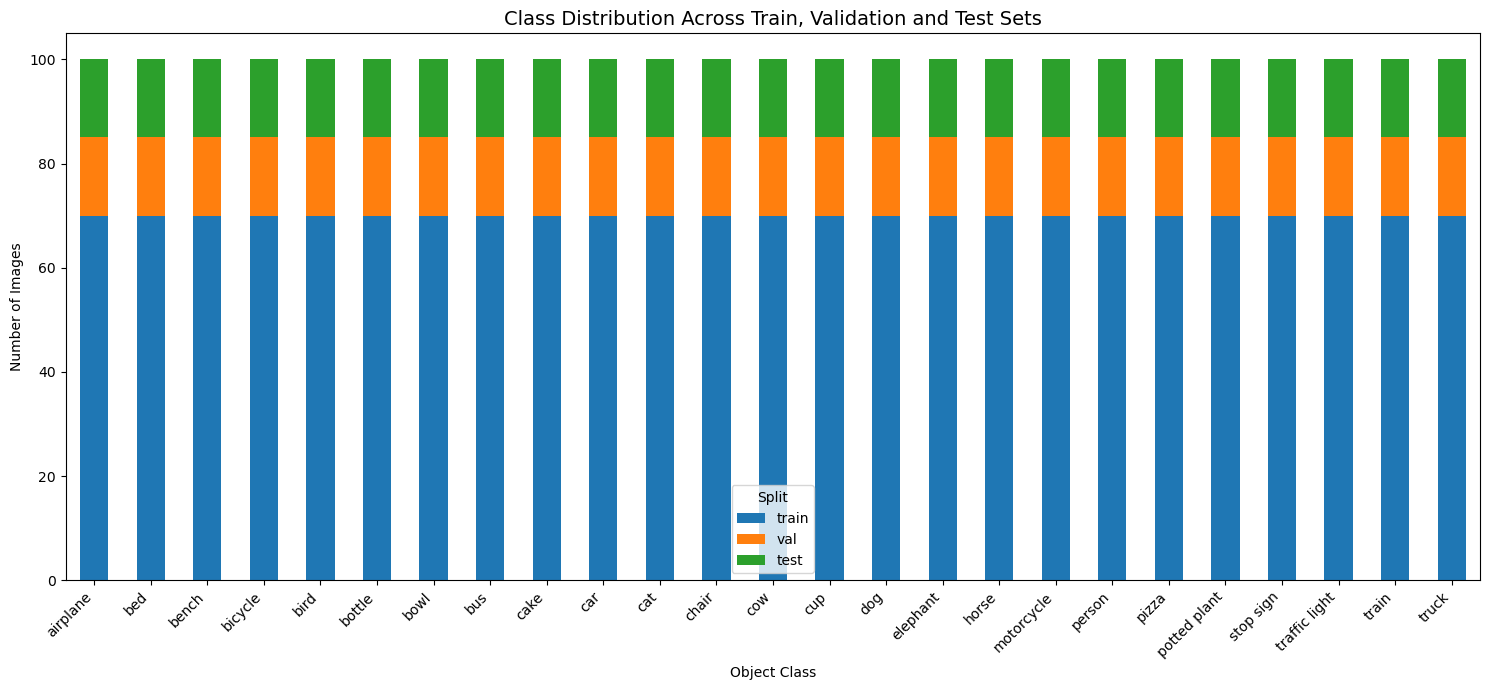

In [3]:
# ============================================================
# EDA CELL 3: CLASS DISTRIBUTION AND BALANCE
# ============================================================

# Count images per class and split
class_distribution = (
    eda_df
    .groupby(["class_name", "split"])
    .size()
    .unstack(fill_value=0)
)

# Keep split order consistent
class_distribution = class_distribution[
    ["train", "val", "test"]
]

# Total images per class
class_distribution["total"] = (
    class_distribution["train"]
    + class_distribution["val"]
    + class_distribution["test"]
)

print("=" * 70)
print("📊 CLASS DISTRIBUTION")
print("=" * 70)

print(class_distribution)

print("\n" + "=" * 70)
print("CLASS BALANCE SUMMARY")
print("=" * 70)

print(
    f"Minimum images per class : "
    f"{class_distribution['total'].min()}"
)

print(
    f"Maximum images per class : "
    f"{class_distribution['total'].max()}"
)

print(
    f"Mean images per class    : "
    f"{class_distribution['total'].mean():.2f}"
)

print(
    f"Std deviation            : "
    f"{class_distribution['total'].std():.2f}"
)

if class_distribution["total"].nunique() == 1:
    print("\n✅ Dataset is perfectly balanced.")
else:
    print("\n⚠️ Dataset contains class imbalance.")


# ------------------------------------------------------------
# Visualization
# ------------------------------------------------------------

plot_df = class_distribution[
    ["train", "val", "test"]
]

ax = plot_df.plot(
    kind="bar",
    stacked=True,
    figsize=(15, 7)
)

plt.title(
    "Class Distribution Across Train, Validation and Test Sets",
    fontsize=14
)

plt.xlabel("Object Class")
plt.ylabel("Number of Images")

plt.xticks(
    rotation=45,
    ha="right"
)

plt.legend(title="Split")

plt.tight_layout()
plt.show()

🖼️ IMAGE CHARACTERISTICS & QUALITY
       file_size_kb  brightness  contrast  sharpness
count       2500.00     2500.00   2500.00    2500.00
mean          25.06      102.30     57.12    3036.68
std            6.41       33.03     14.01    1761.21
min            6.04        3.31     10.59      65.99
25%           20.50       80.00     47.94    1669.95
50%           25.05      102.31     57.11    2784.03
75%           29.55      121.90     66.11    4231.50
max           46.63      225.28    106.70   10178.16

Image properties:
Resolution : 224 × 224
Color mode : RGB
Format     : JPEG


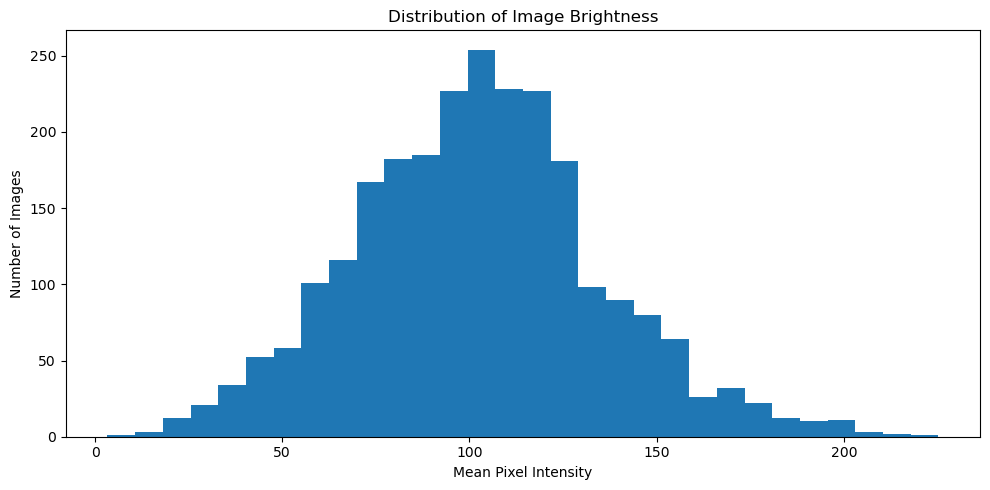

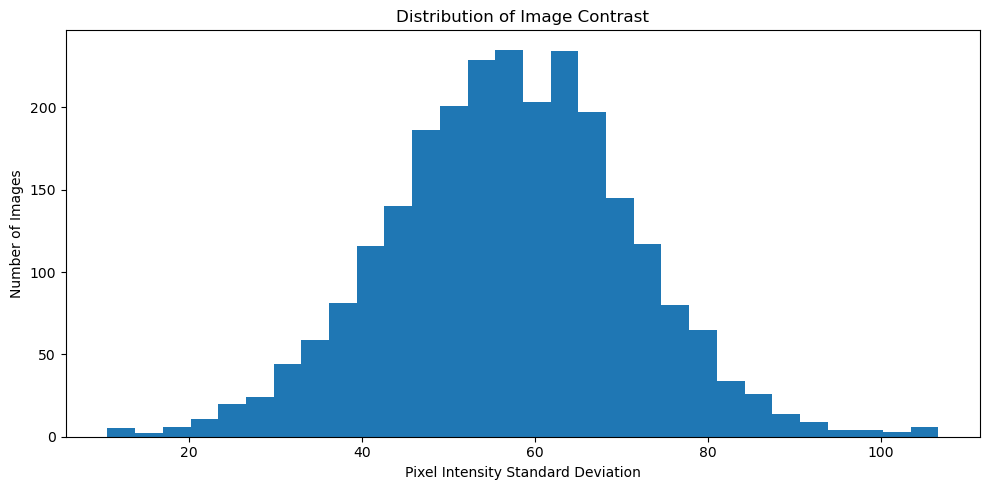

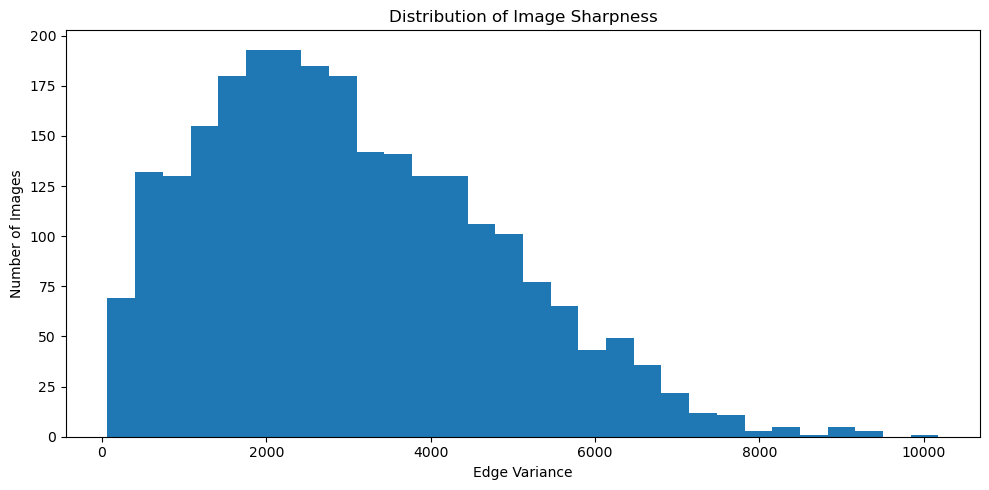

In [4]:
# ============================================================
# EDA CELL 4: IMAGE CHARACTERISTICS AND QUALITY
# ============================================================

from PIL import Image, ImageFilter

quality_records = []

for _, row in eda_df.iterrows():

    with Image.open(row["filepath"]) as img:

        # Convert to grayscale for brightness / contrast analysis
        gray = np.array(img.convert("L"), dtype=np.float32)

        # Mean pixel intensity = brightness
        brightness = gray.mean()

        # Standard deviation = contrast
        contrast = gray.std()

        # Laplacian-like edge strength using FIND_EDGES
        edges = np.array(
            img.convert("L").filter(ImageFilter.FIND_EDGES),
            dtype=np.float32
        )

        sharpness = edges.var()

        quality_records.append({
            "brightness": brightness,
            "contrast": contrast,
            "sharpness": sharpness
        })


quality_df = pd.DataFrame(quality_records)

# Add measurements to main EDA dataframe
eda_df = pd.concat(
    [
        eda_df.reset_index(drop=True),
        quality_df
    ],
    axis=1
)


print("=" * 70)
print("🖼️ IMAGE CHARACTERISTICS & QUALITY")
print("=" * 70)

print(
    eda_df[
        [
            "file_size_kb",
            "brightness",
            "contrast",
            "sharpness"
        ]
    ]
    .describe()
    .round(2)
)

print("\nImage properties:")
print("Resolution : 224 × 224")
print("Color mode : RGB")
print("Format     : JPEG")

print("=" * 70)


# ------------------------------------------------------------
# Distribution plots
# ------------------------------------------------------------

plt.figure(figsize=(10, 5))
plt.hist(eda_df["brightness"], bins=30)
plt.title("Distribution of Image Brightness")
plt.xlabel("Mean Pixel Intensity")
plt.ylabel("Number of Images")
plt.tight_layout()
plt.show()


plt.figure(figsize=(10, 5))
plt.hist(eda_df["contrast"], bins=30)
plt.title("Distribution of Image Contrast")
plt.xlabel("Pixel Intensity Standard Deviation")
plt.ylabel("Number of Images")
plt.tight_layout()
plt.show()


plt.figure(figsize=(10, 5))
plt.hist(eda_df["sharpness"], bins=30)
plt.title("Distribution of Image Sharpness")
plt.xlabel("Edge Variance")
plt.ylabel("Number of Images")
plt.tight_layout()
plt.show()

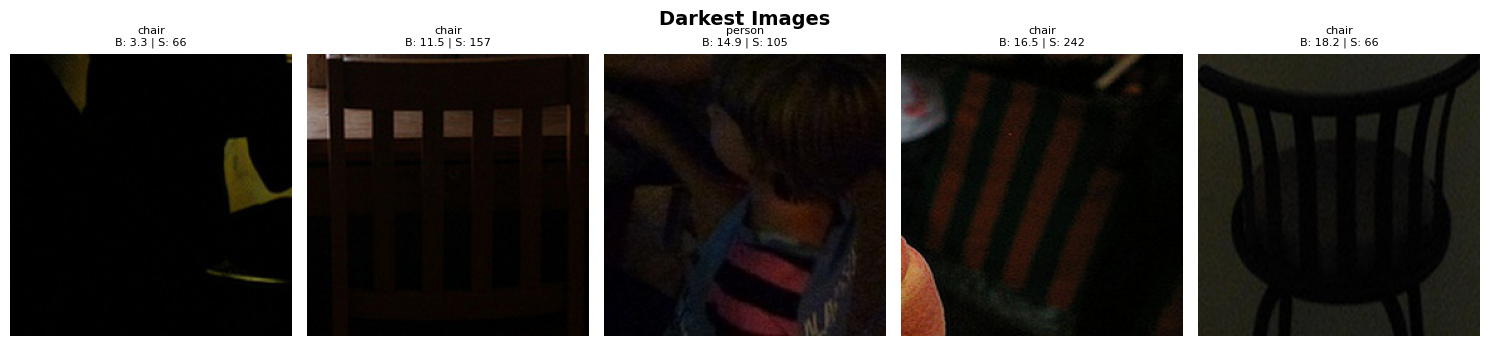

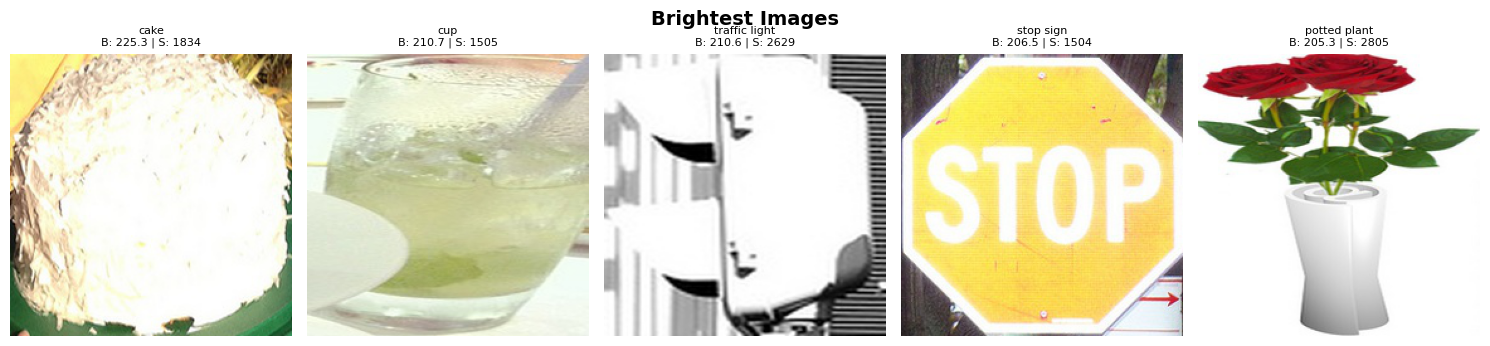

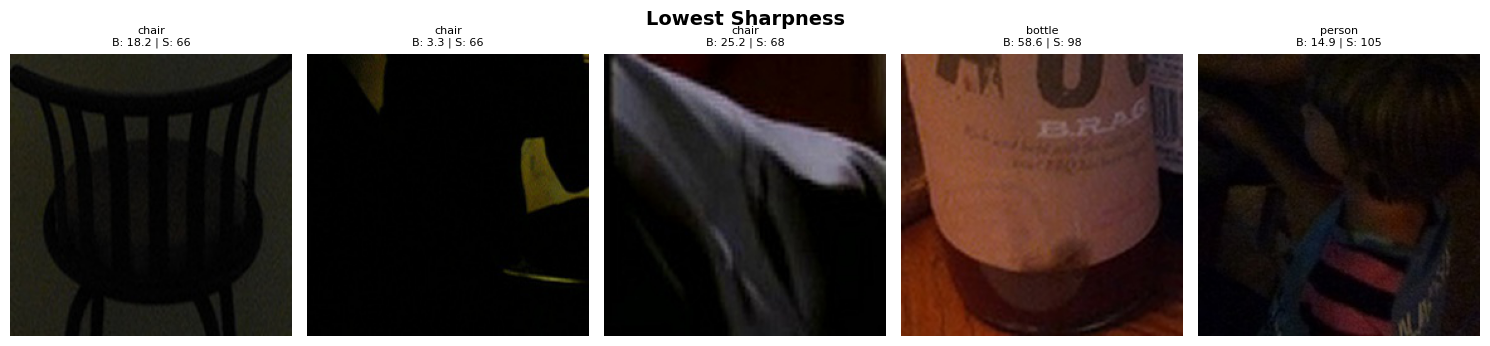

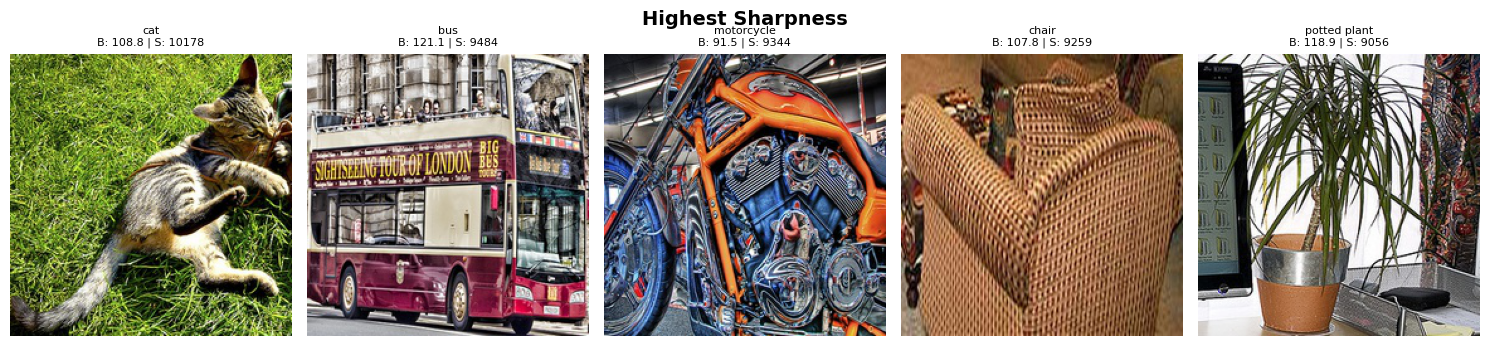

In [5]:
# ============================================================
# EDA CELL 5: VISUALIZE IMAGE QUALITY EXTREMES
# ============================================================

quality_checks = {
    "Darkest Images": eda_df.nsmallest(5, "brightness"),
    "Brightest Images": eda_df.nlargest(5, "brightness"),
    "Lowest Sharpness": eda_df.nsmallest(5, "sharpness"),
    "Highest Sharpness": eda_df.nlargest(5, "sharpness")
}


for title, subset in quality_checks.items():

    fig, axes = plt.subplots(
        1,
        5,
        figsize=(15, 3.5)
    )

    fig.suptitle(
        title,
        fontsize=14,
        fontweight="bold"
    )

    for ax, (_, row) in zip(axes, subset.iterrows()):

        with Image.open(row["filepath"]) as img:
            ax.imshow(img)

        ax.set_title(
            f"{row['class_name']}\n"
            f"B: {row['brightness']:.1f} | "
            f"S: {row['sharpness']:.0f}",
            fontsize=8
        )

        ax.axis("off")

    plt.tight_layout()
    plt.show()

🔍 OBJECTS PER ORIGINAL COCO SOURCE IMAGE
count    1989.00
mean        1.26
std         0.65
min         1.00
25%         1.00
50%         1.00
75%         1.00
max        10.00
Name: object_count, dtype: float64

Frequency distribution:
object_count
1     1620
2      274
3       65
4       21
5        5
6        3
10       1
Name: count, dtype: int64

Unique source images:
1989

Total classification objects:
2500


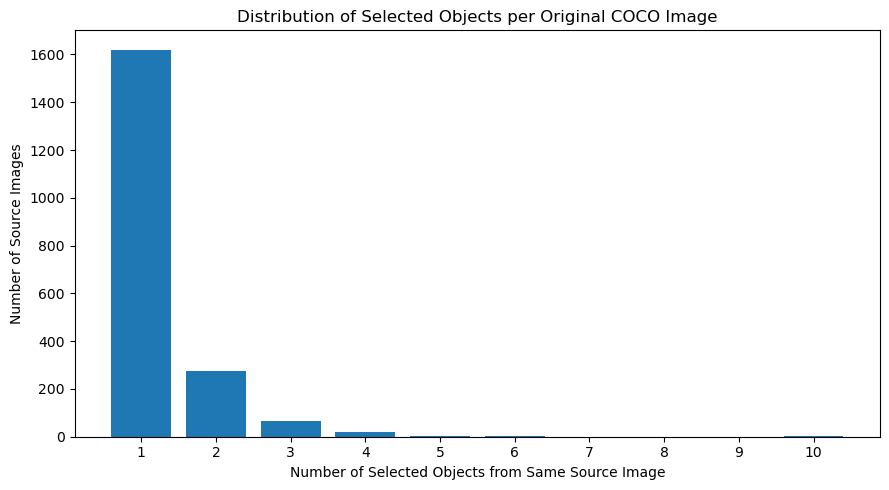

In [6]:
# ============================================================
# EDA CELL 6: OBJECTS PER ORIGINAL SOURCE IMAGE
# ============================================================

# Filename format:
# class_name_SOURCEIDX_NUMBER.jpg
#
# Example:
# airplane_000016_065.jpg
#
# For classes containing underscores such as potted_plant,
# source_idx is always the second-last component.

eda_df["source_idx"] = (
    eda_df["filename"]
    .str.replace(".jpg", "", regex=False)
    .str.split("_")
    .str[-2]
    .astype(int)
)


# ------------------------------------------------------------
# Count selected objects originating from each COCO image
# ------------------------------------------------------------

objects_per_source = (
    eda_df
    .groupby(["split", "source_idx"])
    .size()
    .reset_index(name="object_count")
)


print("=" * 70)
print("🔍 OBJECTS PER ORIGINAL COCO SOURCE IMAGE")
print("=" * 70)

print(
    objects_per_source["object_count"]
    .describe()
    .round(2)
)

print("\nFrequency distribution:")

object_frequency = (
    objects_per_source["object_count"]
    .value_counts()
    .sort_index()
)

print(object_frequency)

print("\nUnique source images:")
print(objects_per_source["source_idx"].nunique())

print("\nTotal classification objects:")
print(objects_per_source["object_count"].sum())

print("=" * 70)


# ------------------------------------------------------------
# Visualization
# ------------------------------------------------------------

plt.figure(figsize=(9, 5))

plt.hist(
    objects_per_source["object_count"],
    bins=range(
        1,
        objects_per_source["object_count"].max() + 2
    ),
    align="left",
    rwidth=0.8
)

plt.title(
    "Distribution of Selected Objects per Original COCO Image"
)

plt.xlabel(
    "Number of Selected Objects from Same Source Image"
)

plt.ylabel("Number of Source Images")

plt.xticks(
    range(
        1,
        objects_per_source["object_count"].max() + 1
    )
)

plt.tight_layout()
plt.show()

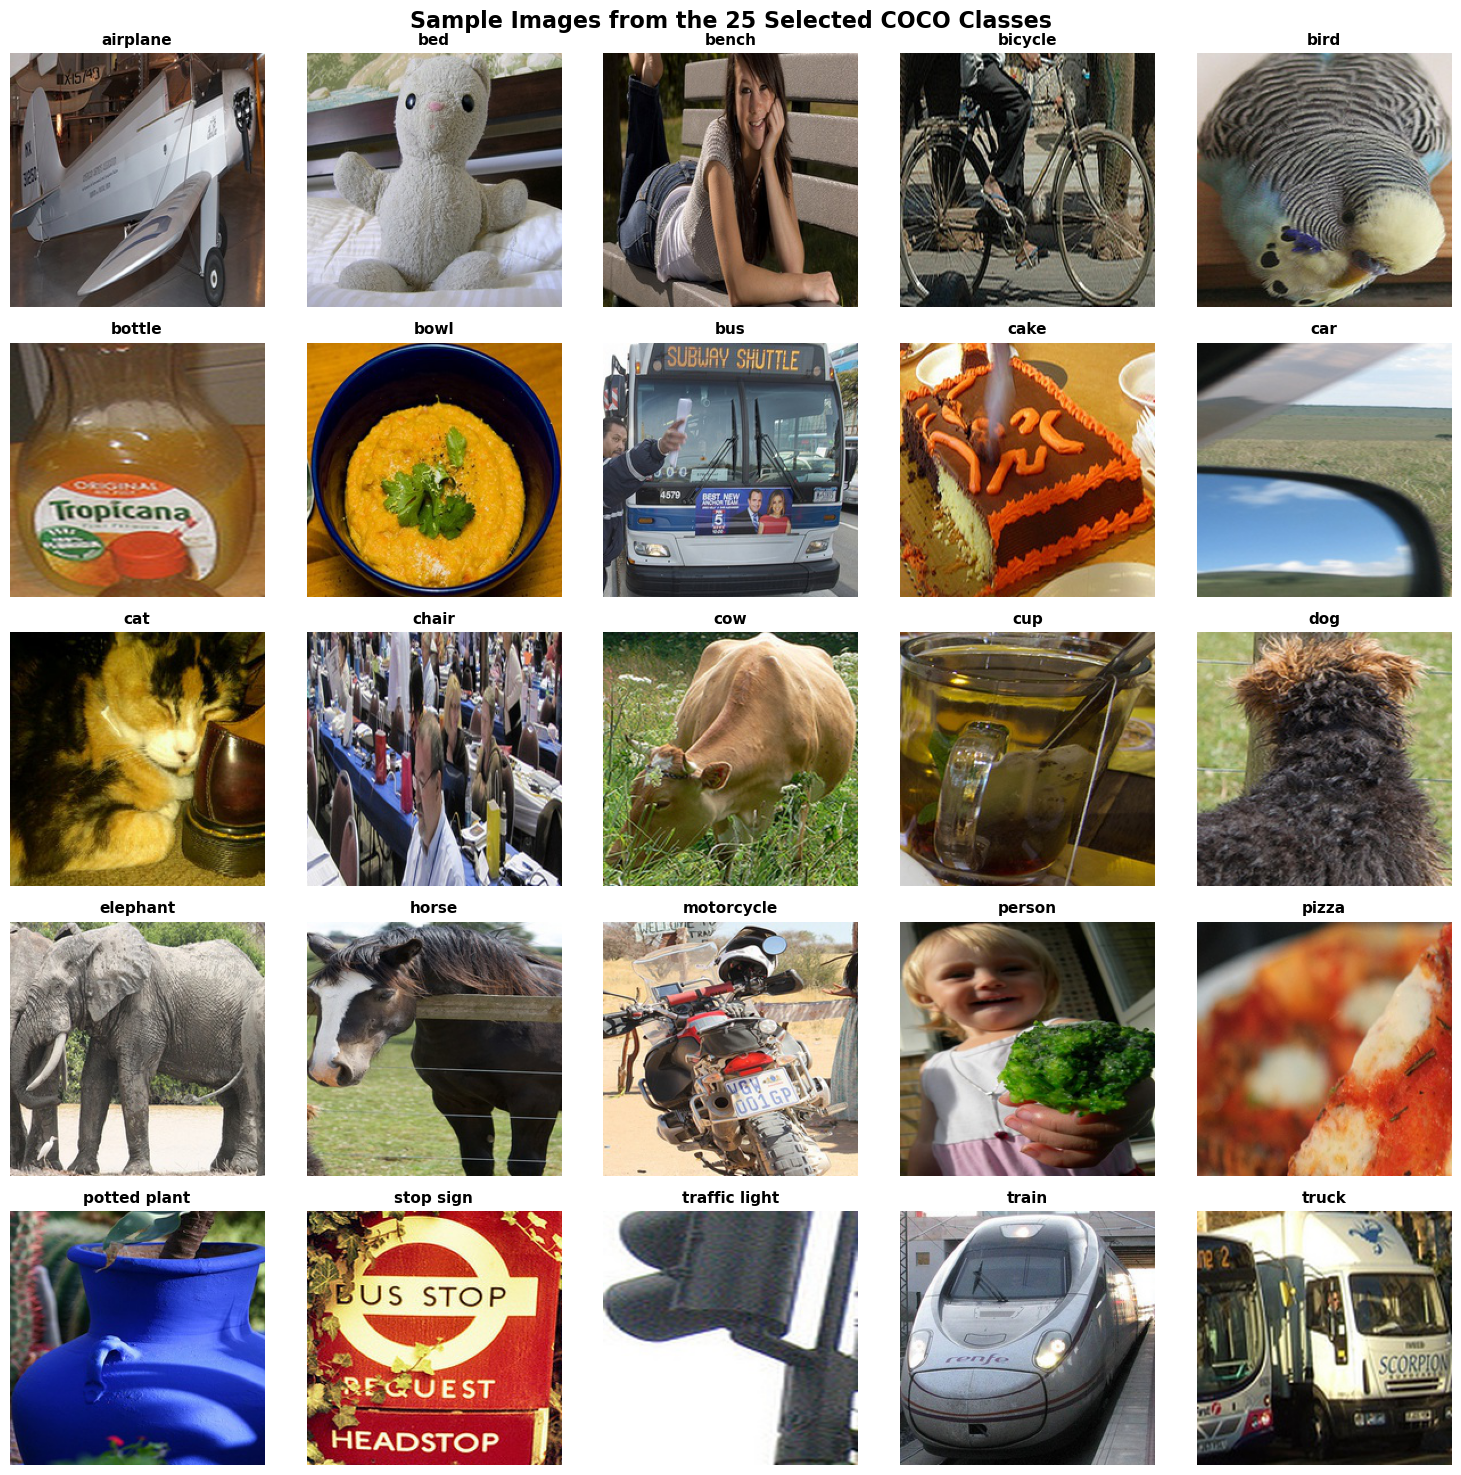

In [7]:
# ============================================================
# EDA CELL 7: SAMPLE VISUALIZATION - ALL 25 CLASSES
# ============================================================

random.seed(42)

class_names = sorted(
    eda_df["class_name"].unique()
)

fig, axes = plt.subplots(
    5,
    5,
    figsize=(15, 15)
)

axes = axes.flatten()

for ax, class_name in zip(axes, class_names):

    # Use training data only for visualization
    class_samples = eda_df[
        (eda_df["split"] == "train") &
        (eda_df["class_name"] == class_name)
    ]

    sample = class_samples.sample(
        n=1,
        random_state=42
    ).iloc[0]

    with Image.open(sample["filepath"]) as img:
        ax.imshow(img)

    ax.set_title(
        class_name,
        fontsize=11,
        fontweight="bold"
    )

    ax.axis("off")


plt.suptitle(
    "Sample Images from the 25 Selected COCO Classes",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

In [8]:
# ============================================================
# EDA CELL 8: FINAL EDA SUMMARY
# ============================================================

total_images = len(eda_df)
num_classes = eda_df["class_name"].nunique()

train_count = (eda_df["split"] == "train").sum()
val_count   = (eda_df["split"] == "val").sum()
test_count  = (eda_df["split"] == "test").sum()

unique_sources = eda_df["source_idx"].nunique()

avg_brightness = eda_df["brightness"].mean()
avg_contrast   = eda_df["contrast"].mean()
avg_sharpness  = eda_df["sharpness"].mean()
avg_file_size  = eda_df["file_size_kb"].mean()

balanced = (
    eda_df.groupby("class_name").size().nunique() == 1
)

print("=" * 75)
print("📋 SMARTVISION AI - FINAL EDA SUMMARY")
print("=" * 75)

print(f"""
Dataset Overview
----------------
Total classification images : {total_images}
Number of classes           : {num_classes}
Images per class            : {total_images // num_classes}

Dataset Split
-------------
Training images             : {train_count}
Validation images           : {val_count}
Test images                 : {test_count}

Image Properties
----------------
Resolution                   : 224 × 224 pixels
Color mode                   : RGB
Image format                 : JPEG
Average file size            : {avg_file_size:.2f} KB

Image Quality Characteristics
-----------------------------
Average brightness           : {avg_brightness:.2f}
Average contrast             : {avg_contrast:.2f}
Average sharpness            : {avg_sharpness:.2f}

Source Image Analysis
---------------------
Unique COCO source images    : {unique_sources}
Selected classification objs : {total_images}
Average objects/source image : {total_images / unique_sources:.2f}

Class Balance
-------------
Balanced dataset             : {"YES" if balanced else "NO"}

Key EDA Findings
----------------
1. The final dataset contains 25 object classes with 100 images per class.
2. Every class follows an exact 70/15/15 train-validation-test split.
3. All classification images are standardized to 224 × 224 RGB JPEG format.
4. The dataset is perfectly class-balanced.
5. Images contain natural variation in brightness, contrast and sharpness.
6. Most COCO source images contribute a single selected classification object.
7. Visual inspection confirms substantial variation in object appearance,
   viewpoint, lighting, scale and surrounding context.
8. Extreme brightness/sharpness samples were visually inspected rather than
   automatically removed.
9. Train, validation and test sets were previously constructed at source-image
   level to prevent source-image leakage.
""")

print("=" * 75)
print("✅ CLASSIFICATION EDA COMPLETED SUCCESSFULLY")
print("=" * 75)

📋 SMARTVISION AI - FINAL EDA SUMMARY

Dataset Overview
----------------
Total classification images : 2500
Number of classes           : 25
Images per class            : 100

Dataset Split
-------------
Training images             : 1750
Validation images           : 375
Test images                 : 375

Image Properties
----------------
Resolution                   : 224 × 224 pixels
Color mode                   : RGB
Image format                 : JPEG
Average file size            : 25.06 KB

Image Quality Characteristics
-----------------------------
Average brightness           : 102.30
Average contrast             : 57.12
Average sharpness            : 3036.68

Source Image Analysis
---------------------
Unique COCO source images    : 1989
Selected classification objs : 2500
Average objects/source image : 1.26

Class Balance
-------------
Balanced dataset             : YES

Key EDA Findings
----------------
1. The final dataset contains 25 object classes with 100 images per class